# ***GÖREV 1***

In [8]:
%pip install -q transformers matplotlib

In [2]:
import torch
import transformers
import matplotlib.pyplot as plt

from transformers import GPT2LMHeadModel

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)

model_hf = GPT2LMHeadModel.from_pretrained(
    "openai-community/gpt2",
    attn_implementation="eager",
)

model_hf.eval()

config = model_hf.config

print("Sözlük büyüklüğü:", config.vocab_size)
print("Maksimum pozisyon:", config.n_positions)
print("Embedding boyutu:", config.n_embd)
print("Transformer blok sayısı:", config.n_layer)
print("Attention head sayısı:", config.n_head)

PyTorch: 2.11.0+cu130
Transformers: 5.20.2


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

Sözlük büyüklüğü: 50257
Maksimum pozisyon: 1024
Embedding boyutu: 768
Transformer blok sayısı: 12
Attention head sayısı: 12


In [5]:
state_dict = model_hf.state_dict()

for name, tensor in state_dict.items():
    print(f"{name:48s} {str(tuple(tensor.shape)):20s}")

transformer.wte.weight                           (50257, 768)        
transformer.wpe.weight                           (1024, 768)         
transformer.h.0.ln_1.weight                      (768,)              
transformer.h.0.ln_1.bias                        (768,)              
transformer.h.0.attn.c_attn.weight               (768, 2304)         
transformer.h.0.attn.c_attn.bias                 (2304,)             
transformer.h.0.attn.c_proj.weight               (768, 768)          
transformer.h.0.attn.c_proj.bias                 (768,)              
transformer.h.0.ln_2.weight                      (768,)              
transformer.h.0.ln_2.bias                        (768,)              
transformer.h.0.mlp.c_fc.weight                  (768, 3072)         
transformer.h.0.mlp.c_fc.bias                    (3072,)             
transformer.h.0.mlp.c_proj.weight                (3072, 768)         
transformer.h.0.mlp.c_proj.bias                  (768,)              
transformer.h.1.ln_1

In [6]:
total_params = sum(p.numel() for p in model_hf.parameters())

print(f"Toplam benzersiz parametre: {total_params:,}")
print(f"Milyon cinsinden: {total_params / 1e6:.3f} M")

shared_weight = (
    model_hf.transformer.wte.weight
    is model_hf.lm_head.weight
)

print("Token embedding ve LM head aynı parametre mi?", shared_weight)

assert total_params == 124_439_808
assert shared_weight

Toplam benzersiz parametre: 124,439,808
Milyon cinsinden: 124.440 M
Token embedding ve LM head aynı parametre mi? True


Pozisyon embedding boyutu: (1024, 768)


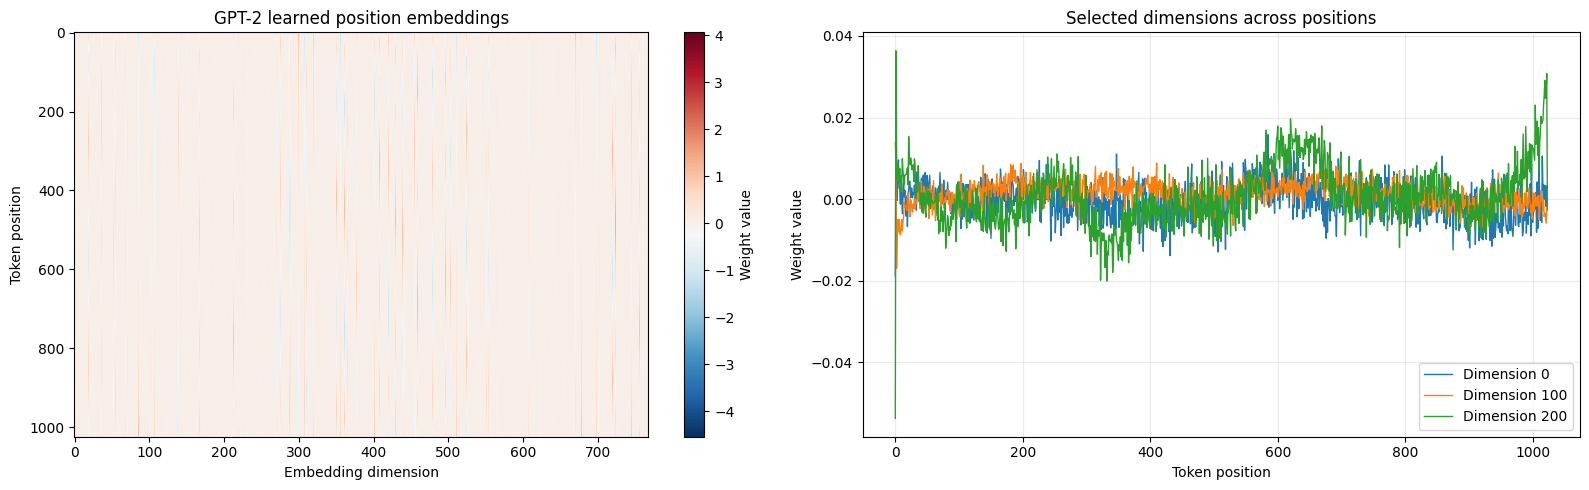

In [7]:
wpe = model_hf.transformer.wpe.weight.detach().cpu().numpy()

print("Pozisyon embedding boyutu:", wpe.shape)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

heatmap = axes[0].imshow(
    wpe,
    aspect="auto",
    cmap="RdBu_r",
    interpolation="nearest",
)

axes[0].set_title("GPT-2 learned position embeddings")
axes[0].set_xlabel("Embedding dimension")
axes[0].set_ylabel("Token position")

fig.colorbar(heatmap, ax=axes[0], label="Weight value")

channels = [0, 100, 200]

for channel in channels:
    axes[1].plot(
        wpe[:, channel],
        label=f"Dimension {channel}",
        linewidth=1,
    )

axes[1].set_title("Selected dimensions across positions")
axes[1].set_xlabel("Token position")
axes[1].set_ylabel("Weight value")
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [8]:
wpe[10]       # 10. pozisyonun 768 boyutlu temsili
wpe[:, 100]  # 100. boyutun bütün pozisyonlardaki değerleri

array([ 0.01378703,  0.00912738, -0.01698616, ..., -0.00590489,
       -0.0027805 , -0.00117183], dtype=float32)

# ***GÖREV 2***

In [9]:
import torch
import torch.nn as nn
from torch.nn import functional as F
from transformers import AutoTokenizer

n_embd = 768
n_head = 12
n_layer = 12
block_size = 1024
vocab_size = 50257
dropout = 0.1


class MultiHeadAttention(nn.Module):
    def __init__(self):
        super().__init__()

        self.c_attn = nn.Linear(n_embd, 3 * n_embd)
        self.proj = nn.Linear(n_embd, n_embd)

        self.attn_dropout = nn.Dropout(dropout)
        self.dropout = nn.Dropout(dropout)

        self.register_buffer(
            "tril",
            torch.tril(torch.ones(block_size, block_size)),
            persistent=False,
        )

    def forward(self, x):
        B, T, C = x.shape
        head_size = C // n_head

        q, k, v = self.c_attn(x).split(C, dim=-1)

        q = q.view(B, T, n_head, head_size).transpose(1, 2)
        k = k.view(B, T, n_head, head_size).transpose(1, 2)
        v = v.view(B, T, n_head, head_size).transpose(1, 2)

        wei = q @ k.transpose(-2, -1) * head_size**-0.5
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float("-inf"))
        wei = F.softmax(wei, dim=-1)
        wei = self.attn_dropout(wei)

        out = wei @ v
        out = out.transpose(1, 2).contiguous().view(B, T, C)

        out = self.proj(out)
        return self.dropout(out)

In [10]:
class FeedFoward(nn.Module):
    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.GELU(approximate="tanh"),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


class Block(nn.Module):
    def __init__(self):
        super().__init__()

        self.sa = MultiHeadAttention()
        self.ffwd = FeedFoward()
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))
        return x


class GPTLanguageModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.token_embedding_table = nn.Embedding(vocab_size, n_embd)
        self.position_embedding_table = nn.Embedding(block_size, n_embd)

        self.dropout = nn.Dropout(dropout)
        self.blocks = nn.Sequential(*[Block() for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)

        self.lm_head = nn.Linear(n_embd, vocab_size, bias=False)
        self.lm_head.weight = self.token_embedding_table.weight

    def forward(self, idx, targets=None):
        B, T = idx.shape
        assert T <= block_size

        tok_emb = self.token_embedding_table(idx)
        pos_emb = self.position_embedding_table(
            torch.arange(T, device=idx.device)
        )

        x = self.dropout(tok_emb + pos_emb)
        x = self.blocks(x)
        x = self.ln_f(x)

        logits = self.lm_head(x)

        loss = None
        if targets is not None:
            loss = F.cross_entropy(
                logits.reshape(B * T, vocab_size),
                targets.reshape(B * T),
            )

        return logits, loss

In [11]:
model_custom = GPTLanguageModel()

hf_weights = model_hf.state_dict()
our_weights = model_custom.state_dict()

mapping = {
    "token_embedding_table.weight": "transformer.wte.weight",
    "position_embedding_table.weight": "transformer.wpe.weight",
    "ln_f.weight": "transformer.ln_f.weight",
    "ln_f.bias": "transformer.ln_f.bias",
    "lm_head.weight": "lm_head.weight",
}

block_mapping = {
    "ln1.weight": "ln_1.weight",
    "ln1.bias": "ln_1.bias",
    "sa.c_attn.weight": "attn.c_attn.weight",
    "sa.c_attn.bias": "attn.c_attn.bias",
    "sa.proj.weight": "attn.c_proj.weight",
    "sa.proj.bias": "attn.c_proj.bias",
    "ln2.weight": "ln_2.weight",
    "ln2.bias": "ln_2.bias",
    "ffwd.net.0.weight": "mlp.c_fc.weight",
    "ffwd.net.0.bias": "mlp.c_fc.bias",
    "ffwd.net.2.weight": "mlp.c_proj.weight",
    "ffwd.net.2.bias": "mlp.c_proj.bias",
}

for i in range(n_layer):
    for our_name, hf_name in block_mapping.items():
        mapping[f"blocks.{i}.{our_name}"] = f"transformer.h.{i}.{hf_name}"

transpose_weights = (
    "attn.c_attn.weight",
    "attn.c_proj.weight",
    "mlp.c_fc.weight",
    "mlp.c_proj.weight",
)

assert set(mapping) == set(our_weights)

with torch.no_grad():
    for our_name, hf_name in mapping.items():
        weight = hf_weights[hf_name]

        if hf_name.endswith(transpose_weights):
            weight = weight.t()

        assert weight.shape == our_weights[our_name].shape
        our_weights[our_name].copy_(weight)

print("Ağırlıklar yüklendi.")
print("Parametre sayısı:", sum(p.numel() for p in model_custom.parameters()))

Ağırlıklar yüklendi.
Parametre sayısı: 124439808


In [12]:
tokenizer = AutoTokenizer.from_pretrained("openai-community/gpt2")

model_hf = model_hf.to("cpu").float().eval()
model_custom = model_custom.to("cpu").float().eval()

text = "Hello, I'm a language model,"
x = tokenizer.encode(text, return_tensors="pt")

with torch.no_grad():
    logits_hf = model_hf(x, use_cache=False).logits
    logits_custom, _ = model_custom(x)

difference = (logits_hf - logits_custom).abs()

print("HF logits:", logits_hf.shape)
print("Bizim logits:", logits_custom.shape)
print("Maksimum fark:", difference.max().item())
print("Ortalama fark:", difference.mean().item())

print(
    "Eşleşiyor mu?",
    torch.allclose(logits_custom, logits_hf, atol=1e-4, rtol=1e-5),
)

torch.testing.assert_close(
    logits_custom,
    logits_hf,
    atol=1e-4,
    rtol=1e-5,
)

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

HF logits: torch.Size([1, 8, 50257])
Bizim logits: torch.Size([1, 8, 50257])
Maksimum fark: 6.103515625e-05
Ortalama fark: 1.9369008441572078e-05
Eşleşiyor mu? True


# ***GÖREV 3***

In [13]:
device = "cuda" if torch.cuda.is_available() else "cpu"

model_custom = model_custom.to(device)
model_custom.eval()

print("Cihaz:", device)


@torch.no_grad()
def generate(text, max_new_tokens=60, top_k=50):
    x = tokenizer.encode(text, return_tensors="pt").to(device)

    for _ in range(max_new_tokens):
        x_cond = x[:, -block_size:]

        logits, _ = model_custom(x_cond)
        logits = logits[:, -1, :]

        top_values, top_indices = torch.topk(logits, top_k, dim=-1)
        probs = F.softmax(top_values, dim=-1)

        selected = torch.multinomial(probs, num_samples=1)
        next_token = torch.gather(top_indices, 1, selected)

        x = torch.cat((x, next_token), dim=1)

        if next_token.item() == tokenizer.eos_token_id:
            break

    return tokenizer.decode(x[0].tolist(), skip_special_tokens=True)

Cihaz: cuda


In [14]:
prompt_en = "Hello, today we are going to talk about artificial intelligence."

torch.manual_seed(1337)

for i in range(3):
    print(f"\nÖrnek {i + 1}:")
    print(generate(prompt_en))


Örnek 1:
Hello, today we are going to talk about artificial intelligence.

We need AI to help us deal with social problems. Unfortunately, that's very difficult to achieve after the advent of machine learning. We may not be a good audience for AI, but artificial intelligence is something new. AI has many good qualities: Its capacity of solving many problems is huge,

Örnek 2:
Hello, today we are going to talk about artificial intelligence.

First of all, I don't mean artificial intelligence.

I mean AI. As a computer scientist and myself we are in the early days of supercomputers. As for computer technology, I believe this is a better technology. In fact, I'd probably say that's where we

Örnek 3:
Hello, today we are going to talk about artificial intelligence. We're going to be talking about quantum computers. In a nutshell, the idea underlying quantum computers is that they are machines, they can perform complex processes using mathematical intelligence and they can perform tasks th

In [15]:
prompt_tr = "Merhaba, bugün yapay zeka hakkında konuşacağız."

torch.manual_seed(1337)

for i in range(3):
    print(f"\nÖrnek {i + 1}:")
    print(generate(prompt_tr))


Örnek 1:
Merhaba, bugün yapay zeka hakkında konuşacağız.

This update contains bugfixes and adds a bugfix for JAVA as an Aircreworks project.

Bugfixes

Fixed a security vulnerability in the vSphere version 0.9.3. This fixes a "diverse amount of performance" security vulnerability in the v

Örnek 2:
Merhaba, bugün yapay zeka hakkında konuşacağız.

Eriş: I've put in my own little checklist of things to try to catch bugs and fix bugs before releasing them to the public, so in the future I'll send you something to try to do it by yourself.

Eriş and her team have created the first

Örnek 3:
Merhaba, bugün yapay zeka hakkında konuşacağız. Yüyün nıızığağrız yağızız. Zıyıy çöryşağrız. Yalçıznış yalızamikaz. Yalçıny


In [16]:
%pip install -q tiktoken

In [17]:
for language, text in [("İngilizce", prompt_en), ("Türkçe", prompt_tr)]:
    ids = tokenizer.encode(text, add_special_tokens=False)
    word_count = len(text.split())

    print("\nDil:", language)
    print("Metin:", text)
    print("Kelime sayısı:", word_count)
    print("GPT-2 token sayısı:", len(ids))
    print("Token / kelime:", round(len(ids) / word_count, 2))

tr_ids = tokenizer.encode(prompt_tr, add_special_tokens=False)

print("\nTürkçe token ID'leri:")
print(tr_ids)

print("\nTokenizer parçaları:")
print(tokenizer.convert_ids_to_tokens(tr_ids))

print("\nGeri çözülen metin:")
print(tokenizer.decode(tr_ids, clean_up_tokenization_spaces=False))


Dil: İngilizce
Metin: Hello, today we are going to talk about artificial intelligence.
Kelime sayısı: 10
GPT-2 token sayısı: 12
Token / kelime: 1.2

Dil: Türkçe
Metin: Merhaba, bugün yapay zeka hakkında konuşacağız.
Kelime sayısı: 6
GPT-2 token sayısı: 25
Token / kelime: 4.17

Türkçe token ID'leri:
[13102, 5976, 64, 11, 5434, 9116, 77, 331, 499, 323, 1976, 38001, 387, 28747, 30102, 45658, 479, 261, 84, 46481, 22260, 33133, 30102, 89, 13]

Tokenizer parçaları:
['Mer', 'hab', 'a', ',', 'Ġbug', 'Ã¼', 'n', 'Ġy', 'ap', 'ay', 'Ġz', 'eka', 'Ġha', 'kk', 'Ä±', 'nda', 'Ġk', 'on', 'u', 'ÅŁ', 'aca', 'ÄŁ', 'Ä±', 'z', '.']

Geri çözülen metin:
Merhaba, bugün yapay zeka hakkında konuşacağız.


In [18]:
import tiktoken

enc = tiktoken.get_encoding("cl100k_base")

for language, text in [("İngilizce", prompt_en), ("Türkçe", prompt_tr)]:
    gpt2_ids = tokenizer.encode(text, add_special_tokens=False)
    cl100k_ids = enc.encode(text)
    word_count = len(text.split())

    print("\nDil:", language)
    print("GPT-2:", len(gpt2_ids), "token")
    print("cl100k_base:", len(cl100k_ids), "token")
    print("GPT-2 token/kelime:", round(len(gpt2_ids) / word_count, 2))
    print("cl100k token/kelime:", round(len(cl100k_ids) / word_count, 2))


Dil: İngilizce
GPT-2: 12 token
cl100k_base: 12 token
GPT-2 token/kelime: 1.2
cl100k token/kelime: 1.2

Dil: Türkçe
GPT-2: 25 token
cl100k_base: 19 token
GPT-2 token/kelime: 4.17
cl100k token/kelime: 3.17


# ***GÖREV 4***

In [19]:
import math

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(1337)

# Hazır modeli GPU'dan alıyoruz; ağırlıkları korunuyor.
model_custom.to("cpu")

model_train = GPTLanguageModel()

for name, parameter in model_train.named_parameters():
    if parameter.dim() == 2:
        std = 0.02

        if name.endswith(("sa.proj.weight", "ffwd.net.2.weight")):
            std /= math.sqrt(2 * n_layer)

        nn.init.normal_(parameter, mean=0.0, std=std)

    elif name.endswith("bias"):
        nn.init.zeros_(parameter)

    else:
        nn.init.ones_(parameter)

# Tek batch ezberleme testinde dropout'u kapatıyoruz.
for module in model_train.modules():
    if isinstance(module, nn.Dropout):
        module.p = 0.0

model_train = model_train.to(device)

print("Cihaz:", device)
print("Parametre sayısı:", sum(p.numel() for p in model_train.parameters()))

Cihaz: cuda
Parametre sayısı: 124439808


In [21]:
from urllib.request import urlopen

url = (
    "https://raw.githubusercontent.com/karpathy/"
    "char-rnn/master/data/tinyshakespeare/input.txt"
)

text = urlopen(url).read().decode("utf-8")

tokens = tokenizer.encode(text[:1000], add_special_tokens=False)

B = 1
T = 64

buffer = torch.tensor(
    tokens[:B * T + 1],
    dtype=torch.long,
    device=device,
)

assert buffer.numel() == B * T + 1

x = buffer[:-1].reshape(B, T)
y = buffer[1:].reshape(B, T)

print("x boyutu:", x.shape)
print("y boyutu:", y.shape)

print("\nİlk 10 giriş tokenı:", x[0, :10].tolist())
print("İlk 10 hedef token:", y[0, :10].tolist())

print("\nGirdi metni:")
print(tokenizer.decode(x[0].tolist()))

x boyutu: torch.Size([1, 64])
y boyutu: torch.Size([1, 64])

İlk 10 giriş tokenı: [5962, 22307, 25, 198, 8421, 356, 5120, 597, 2252, 11]
İlk 10 hedef token: [22307, 25, 198, 8421, 356, 5120, 597, 2252, 11, 3285]

Girdi metni:
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Cai


In [23]:
model_train.eval()

with torch.no_grad():
    _, loss = model_train(x, y)

initial_loss = loss.item()
uniform_loss = math.log(vocab_size)

print(f"İlk loss: {initial_loss:.4f}")
print(f"ln({vocab_size}): {uniform_loss:.4f}")
print(f"Fark: {initial_loss - uniform_loss:.4f}")

İlk loss: 11.1186
ln(50257): 10.8249
Fark: 0.2937


In [24]:
optimizer = torch.optim.AdamW(
    model_train.parameters(),
    lr=3e-4,
    weight_decay=0.0,
)

model_train.train()
losses = []

for step in range(300):
    optimizer.zero_grad(set_to_none=True)

    _, loss = model_train(x, y)

    loss.backward()
    optimizer.step()

    losses.append(loss.item())

    if step % 50 == 0:
        print(f"Adım {step}: loss {loss.item():.4f}")

model_train.eval()

with torch.no_grad():
    logits, loss = model_train(x, y)

final_loss = loss.item()
losses.append(final_loss)

predictions = logits.argmax(dim=-1)
accuracy = (predictions == y).float().mean().item()

print(f"\nBaşlangıç loss: {initial_loss:.4f}")
print(f"300 güncelleme sonrası loss: {final_loss:.4f}")
print(f"Aynı batch üzerindeki doğruluk: %{100 * accuracy:.2f}")

Adım 0: loss 11.1186
Adım 50: loss 0.0089
Adım 100: loss 0.0027
Adım 150: loss 0.0019
Adım 200: loss 0.0014
Adım 250: loss 0.0011

Başlangıç loss: 11.1186
300 güncelleme sonrası loss: 0.0009
Aynı batch üzerindeki doğruluk: %100.00


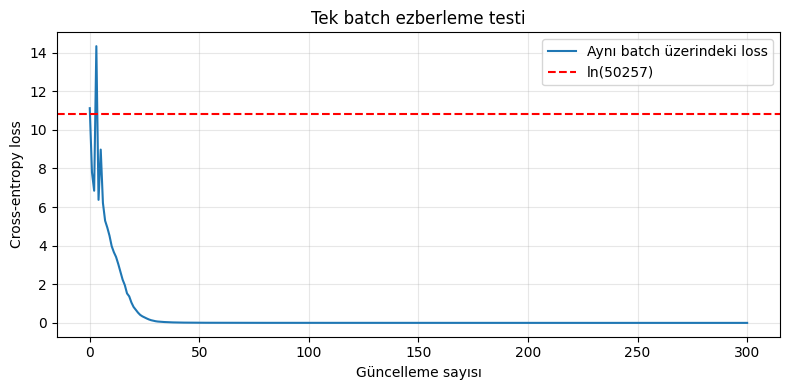

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))

plt.plot(losses, label="Aynı batch üzerindeki loss")

plt.axhline(
    uniform_loss,
    color="red",
    linestyle="--",
    label="ln(50257)",
)

plt.xlabel("Güncelleme sayısı")
plt.ylabel("Cross-entropy loss")
plt.title("Tek batch ezberleme testi")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()